<a href="https://colab.research.google.com/github/araujopedro3/-Projeto-Big-Data-/blob/main/Parte2_Busca_em_Escala_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 2 — Busca em escala: Spark, índice hash (NoSQL chave-valor) e qualidade das chaves

**Disciplina:** Introdução ao Big Data — Engenharia de Software (UNIVEL), 2º período  
**Professor:** Lucas Soares da Silva  
**Pergunta do trabalho:** qual estratégia de busca uma empresa deve adotar para localizar pedidos em uma base que cresce além da memória de uma máquina?

**Como usar (Google Colab):** execute as células **em ordem**. A única interação manual é o envio do arquivo `dados_vendas_sujos.csv` (Etapa 4). O notebook roda de ponta a ponta sem outros arquivos.

**Protocolo de medição (enunciado):** Google Colab; `timeit` só sobre a operação de busca; ordenação e construção do índice medidas à parte; no Spark a busca inclui `count`; 3 repetições por N registrando a **média**; alvo presente e alvo ausente; `num_comp` quando o algoritmo permitir.

> `MODO_TESTE` (célula seguinte) existe só para validar o código com tamanhos minúsculos. **Resultados obtidos com `MODO_TESTE = True` nunca devem entrar no relatório.**

In [1]:
# ============================================================
# SETUP: bibliotecas, parâmetros globais e captura do ambiente
# ============================================================
import os, sys, math, time, timeit, json, re, gc, platform, subprocess, textwrap, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil

# True = tamanhos minúsculos (apenas para testar o código). Deixe False para as medições reais.
MODO_TESTE = os.environ.get("NB_TESTE") == "1"

SEMENTE = 2026                      # reprodutibilidade (mesma semente da parte 1)
rng = np.random.default_rng(SEMENTE)
REPETICOES = 3                      # protocolo: 3 repetições por N, registrando a MÉDIA
SAIDA = "saidas_parte2"             # pasta com tabelas, gráficos e arquivos gerados
os.makedirs(SAIDA, exist_ok=True)

vm = psutil.virtual_memory()
AMBIENTE = {
    "colab": "google.colab" in sys.modules,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "nucleos_cpu": os.cpu_count(),
    "ram_total_gib": round(vm.total / 2**30, 3),
    "ram_disponivel_gib": round(vm.available / 2**30, 3),
    "modo_teste": MODO_TESTE,
}
print(json.dumps(AMBIENTE, indent=2, ensure_ascii=False))
if MODO_TESTE:
    print("\n*** MODO_TESTE ATIVO: não use estes números no relatório ***")

{
  "colab": true,
  "python": "3.13.18",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "nucleos_cpu": 2,
  "ram_total_gib": 12.671,
  "ram_disponivel_gib": 11.644,
  "modo_teste": false
}


In [2]:
# PySpark e Java (no Colab o Java já costuma estar instalado; o pyspark pode precisar de pip)
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
    import pyspark
print("PySpark", pyspark.__version__)
try:
    print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])
except FileNotFoundError:
    print("Java NÃO encontrado. No Colab rode:  !apt-get install -y openjdk-17-jre-headless")

PySpark 4.0.5
openjdk version "21.0.12.1" 2026-08-18


## Funções de busca (reaproveitadas da parte 1)

Código da parte 1, sem alteração de lógica: retornam `(índice, num_comp)`, com índice `-1` para ausência. **Jump e Binária exigem vetor em ordem crescente.** `num_comp` conta comparações entre chave e alvo; a Binária conta igualdade e ordem separadamente.

In [3]:
def busca_sequencial(arr, target):
    num_comp = 0
    for i in range(len(arr)):
        num_comp += 1
        if arr[i] == target:
            return i, num_comp
    return -1, num_comp

def jump_search(arr, target):
    # Pré-condição: arr em ordem crescente. Aceita vetor vazio.
    n = len(arr)
    salto = max(1, math.isqrt(n))
    inicio, fim, num_comp = 0, salto, 0
    while inicio < n:
        num_comp += 1
        if arr[min(fim, n) - 1] >= target:
            break
        inicio = fim
        fim += salto
    for i in range(inicio, min(fim, n)):
        num_comp += 1
        if arr[i] == target:
            return i, num_comp
    return -1, num_comp

def busca_binaria(arr, target):
    # Pré-condição: arr em ordem crescente.
    low, high, num_comp = 0, len(arr) - 1, 0
    while low <= high:
        mid = (low + high) // 2
        num_comp += 1
        if arr[mid] == target:
            return mid, num_comp
        num_comp += 1
        if arr[mid] < target:
            low = mid + 1
        else:
            high = mid - 1
    return -1, num_comp

def _testes_de_correcao():
    # N de 0 a 64: presentes, ausentes (ímpares e extremos) e duplicatas
    for n in range(0, 65):
        arr = np.arange(0, 2 * n, 2)                       # pares; ímpares são ausentes
        for f in (busca_sequencial, jump_search, busca_binaria):
            for i, v in enumerate(arr):
                assert f(arr, v)[0] == i, (f.__name__, n, v)
            for v in (-1, 1, 2 * n - 1, 2 * n, 2 * n + 1):
                if v % 2 == 1 or v < 0 or v >= 2 * n:
                    assert f(arr, v)[0] == -1, (f.__name__, n, v)
    dup = np.array([1, 2, 2, 2, 3, 3, 9])
    for f in (busca_sequencial, jump_search, busca_binaria):
        for v in (1, 2, 3, 9):
            assert dup[f(dup, v)[0]] == v
        assert f(dup, 5)[0] == -1
    print("Testes de correção: OK")
_testes_de_correcao()

Testes de correção: OK


## Ferramenta de medição

`tempo_por_consulta` mede **só a busca**: um *lote* de alvos é executado com `timeit.repeat` (**3 repetições**) e devolve a **média** por consulta. Para algoritmos muito rápidos (hash, Binária), cada repetição executa o lote `k` vezes para ficar acima da resolução do relógio; o tempo é dividido por `k × tamanho do lote`. Os algoritmos lentos (Sequencial em N grande) usam `k = 1`.

In [4]:
def tempo_por_consulta(f, alvos, reps=REPETICOES, alvo_ms=20, calibrar=True):
    """Média (de `reps` repetições) do tempo por consulta, em segundos. `f(alvo)` faz UMA busca."""
    def lote():
        for a in alvos:
            f(a)
    k = 1
    if calibrar:                                   # aquecimento + escolha de k
        t0 = time.perf_counter(); lote(); t1 = time.perf_counter() - t0
        k = int(min(2000, max(1, (alvo_ms / 1000) / max(t1, 1e-9))))
    ts = timeit.repeat(lote, number=k, repeat=reps)
    return float(np.mean(ts)) / (k * len(alvos))

def comparacoes_medias(func_busca, arr, alvos):
    """Média de num_comp sobre os alvos (execução única, fora do timeit)."""
    return float(np.mean([func_busca(arr, a)[1] for a in alvos]))

## Etapa 1 — Retomada da parte 1 e ponto de ruptura

O ponto de ruptura foi documentado na parte 1 (relatório, seção 7). Os valores abaixo são **os registrados lá**, com data e fonte; não são medições novas. Há um teste opcional (`EXECUTAR_ESTRESSE_RAM`) que refaz a ruptura **dobrando N**, como o enunciado pede para quem não a documentou.

Dois pontos de ruptura diferentes, que não devem ser confundidos:
1. **Acúmulo de arrays** (o que a parte 1 mediu): ~1,44 × 10⁹ elementos int64.
2. **Estratégia de busca em memória** (Jump/Binária): precisa do vetor original **e** da cópia ordenada (≥ 16N bytes, mais temporários do `np.sort`). Quebra antes.

In [6]:
PARTE1 = {
    "execucao_utc": "2026-09-17 00:45:41",
    "ram_total_gib": 12.671,
    "ultimo_sucesso_elementos": 1_442_840_576,   # 10,75 GiB de int64
    "primeira_falha_elementos": 1_476_395_008,   # 11 GiB, OOM no cgroup jupyter-children
    "fonte": "Relatório da parte 1, seção 7 (ensaio de blocos de 256 MiB)",
}
N_RUPTURA = PARTE1["ultimo_sucesso_elementos"]

n_max_um_vetor = int(vm.total // 8)           # teto teórico de um único vetor int64
n_max_estrategia = int(vm.total // 16)        # original + ordenado (sem contar temporários do sort)
print(f"RAM total desta sessão: {vm.total/2**30:.3f} GiB (parte 1: {PARTE1['ram_total_gib']} GiB)")
print(f"Ruptura medida na parte 1 (acúmulo de arrays): {N_RUPTURA:,} elementos")
print(f"Teto teórico, 1 vetor int64 : {n_max_um_vetor:,}")
print(f"Teto teórico, original+ordenado (16N bytes): {n_max_estrategia:,}")

# ---- Teste opcional: dobra N até falhar (processo filho; o notebook sobrevive) ----
EXECUTAR_ESTRESSE_RAM = False   # True só se precisar documentar a ruptura de novo. Pode levar minutos.
CODIGO_FILHO = """
import numpy as np, sys
n = int(sys.argv[1]); n_max = int(sys.argv[2])
while n <= n_max:
    a = np.arange(n, dtype=np.int64)[::-1].copy()   # original (desordenado)
    b = np.sort(a)                                  # cópia ordenada: custo real da estratégia
    print(n, flush=True)
    del a, b
    n *= 2
"""
def teste_ruptura_dobrando(n_inicial=10**6, n_max=2**33):
    def _preexec():  # prioriza matar o filho, poupando o notebook
        with open("/proc/self/oom_score_adj", "w") as f:
            f.write("1000")
    r = subprocess.run([sys.executable, "-c", CODIGO_FILHO, str(n_inicial), str(n_max)],
                       capture_output=True, text=True, preexec_fn=_preexec)
    ok = [int(x) for x in r.stdout.split()]
    return {"ultimo_N_ok": ok[-1] if ok else None, "retorno": r.returncode,
            "erro": r.stderr.strip()[-300:]}
if EXECUTAR_ESTRESSE_RAM:
    resultado_ruptura = teste_ruptura_dobrando()
    print("Ruptura da ESTRATÉGIA (original + ordenado), dobrando N:", resultado_ruptura)
else:
    print("Teste de ruptura desativado; usando o registro da parte 1 acima.")

RAM total desta sessão: 12.671 GiB (parte 1: 12.671 GiB)
Ruptura medida na parte 1 (acúmulo de arrays): 1,442,840,576 elementos
Teto teórico, 1 vetor int64 : 1,700,726,272
Teto teórico, original+ordenado (16N bytes): 850,363,136
Teste de ruptura desativado; usando o registro da parte 1 acima.


## Etapa 2 — Além da ruptura com Spark

**O que esta etapa mede:** o tempo de buscar um alvo com `spark.range(N).filter(id == alvo).count()` e o compara com as três buscas da parte 1 nos N em que ambas rodam.

**Leitura honesta dos resultados (vale para o relatório):**
- `spark.range` é **preguiçoso**: gera os ids por partição, sob demanda, e **não materializa os N valores em RAM**. É isso que o faz continuar funcionando onde o vetor em memória falha. Isso demonstra processamento por partições/lotes; **não demonstra distribuição**.
- No Colab o Spark roda em `local[*]`: **uma única máquina**, só com mais de um núcleo. Não é um cluster.
- `filter` + `count` percorre **todos** os dados, com alvo presente ou ausente (não há parada antecipada como na Sequencial).
- Em N pequeno, o custo fixo de agendamento (JVM, jobs) tende a dominar; o ganho só aparece em N grande.
- Nos N em que o vetor não cabe em RAM (acima da ruptura) a Sequencial **não é executada**: registra-se "não cabe" pela conta de memória (8N bytes por vetor) e pela evidência da parte 1.

In [7]:
RODAR_SPARK = True
N_ACIMA = 3_000_000 if MODO_TESTE else 2_000_000_000        # deve ficar ACIMA da ruptura
SPARK_NS = [10**5, 10**6, N_ACIMA] if MODO_TESTE else [10**6, 10**7, 10**8, 10**9, N_ACIMA]
SEQ_MAX_N = 10**6 if MODO_TESTE else 10**8                  # Sequencial em Python: acima disso leva horas
assert MODO_TESTE or N_ACIMA > N_RUPTURA, "N_ACIMA precisa superar o ponto de ruptura"

def medir_numpy_em_N(N):
    """Sequencial, Jump e Binária sobre np.arange(N) (já ordenado: sem custo de ordenação aqui)."""
    arr = np.arange(N, dtype=np.int64)
    linhas = []
    cfg = {  # (função, alvos presentes, calibrar)
        "Sequencial": (busca_sequencial, rng.choice(N, size=min(3, N), replace=False).tolist(), False),
        "Jump":       (jump_search,      rng.choice(N, size=min(64, N), replace=False).tolist(), True),
        "Binária":    (busca_binaria,    rng.choice(N, size=min(64, N), replace=False).tolist(), True),
    }
    for nome, (f, presentes, calibrar) in cfg.items():
        for caso, alvos in (("presente", presentes), ("ausente", [-1])):
            t = tempo_por_consulta(lambda a: f(arr, a), alvos, calibrar=calibrar)
            linhas.append(dict(N=N, algoritmo=nome, caso=caso, tempo_medio_s=t,
                               num_comp=comparacoes_medias(f, arr, alvos),
                               alvos_na_amostra=len(alvos), obs=""))
    del arr; gc.collect()
    return linhas

def medir_spark_em_N(spark, F, N):
    df = spark.range(N)                                       # lazy: nada é materializado aqui
    linhas = []
    for caso, alvo, esperado in (("presente", N // 2, 1), ("ausente", -1, 0)):
        saida = []
        def f():
            saida.append(df.filter(F.col("id") == alvo).count())   # count dispara a execução
        ts = timeit.repeat(f, number=1, repeat=REPETICOES)
        assert all(r == esperado for r in saida), (N, caso, saida)  # conferência de correção
        linhas.append(dict(N=N, algoritmo="Spark filter", caso=caso, tempo_medio_s=float(np.mean(ts)),
                           num_comp=np.nan, alvos_na_amostra=1, obs=""))
    return linhas

linhas_spark = []
if RODAR_SPARK:
    from pyspark.sql import SparkSession, functions as F
    mem_gb = max(1, int(vm.total * 0.6 / 2**30))
    spark = (SparkSession.builder.master("local[*]").appName("busca_parte2")
             .config("spark.driver.memory", f"{mem_gb}g").config("spark.ui.enabled", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    AMBIENTE["spark"] = {"versao": spark.version, "nucleos_defaultParallelism": spark.sparkContext.defaultParallelism,
                         "driver_memory": f"{mem_gb}g", "modo": "local[*] (uma máquina)"}
    print("Spark:", AMBIENTE["spark"])
    spark.range(1000).filter(F.col("id") == 1).count()        # aquecimento da JVM (fora das medições)

    for N in SPARK_NS:
        t0 = time.time()
        linhas_spark += medir_spark_em_N(spark, F, N)
        if N <= SEQ_MAX_N and 16 * N < vm.available:
            linhas_spark += medir_numpy_em_N(N)
        else:
            motivo = (f"não executada: vetor de {8*N/2**30:.1f} GiB (16N com ordenado = {16*N/2**30:.1f} GiB) "
                      f"vs RAM total {vm.total/2**30:.1f} GiB" if 16 * N >= vm.available
                      else f"não executada: Sequencial em Python seria impraticável (limite do experimento = {SEQ_MAX_N:,})")
            for alg in ("Sequencial", "Jump", "Binária"):
                linhas_spark.append(dict(N=N, algoritmo=alg, caso="-", tempo_medio_s=np.nan, num_comp=np.nan,
                                         alvos_na_amostra=0, obs=motivo))
        print(f"N = {N:,} concluído em {time.time()-t0:.1f} s")

tabela_spark = pd.DataFrame(linhas_spark)
tabela_spark.to_csv(f"{SAIDA}/tabela_spark.csv", index=False)
tabela_spark

Spark: {'versao': '4.0.5', 'nucleos_defaultParallelism': 2, 'driver_memory': '7g', 'modo': 'local[*] (uma máquina)'}
N = 1,000,000 concluído em 4.9 s
N = 10,000,000 concluído em 18.6 s
N = 100,000,000 concluído em 128.3 s
N = 1,000,000,000 concluído em 4.5 s
N = 2,000,000,000 concluído em 5.8 s


,N,algoritmo,caso,tempo_medio_s,num_comp,alvos_na_amostra,obs
0,1000000,Spark filter,presente,0.623284,NaN,1,
1,1000000,Spark filter,ausente,0.493048,NaN,1,
2,1000000,Sequencial,presente,0.050983,3.524013e+05,3,
3,1000000,Sequencial,ausente,0.147010,1.000000e+06,1,
4,1000000,Jump,presente,0.000184,1.038688e+03,64,
5,1000000,Jump,ausente,0.000140,1.001000e+03,1,
6,1000000,Binária,presente,0.000006,3.728125e+01,64,
7,1000000,Binária,ausente,0.000006,3.800000e+01,1,
8,10000000,Spark filter,presente,0.259832,NaN,1,
9,10000000,Spark filter,ausente,0.239098,NaN,1,


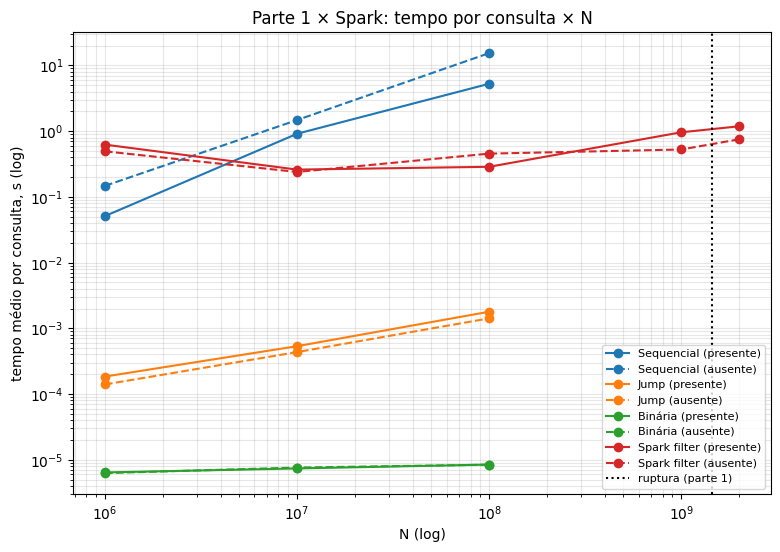

In [8]:
# Tabela N × algoritmo × tempo (formato pedido pelo protocolo) e gráfico log-log
if len(tabela_spark):
    pivo = (tabela_spark[tabela_spark.caso != "-"]
            .pivot_table(index="N", columns=["algoritmo", "caso"], values="tempo_medio_s"))
    display(pivo.style.format("{:.6g}"))

    fig, ax = plt.subplots(figsize=(9, 6))
    estilos = {"Sequencial": "tab:blue", "Jump": "tab:orange", "Binária": "tab:green", "Spark filter": "tab:red"}
    for alg, cor in estilos.items():
        for caso, ls in (("presente", "-"), ("ausente", "--")):
            d = tabela_spark[(tabela_spark.algoritmo == alg) & (tabela_spark.caso == caso)].dropna(subset=["tempo_medio_s"])
            if len(d):
                ax.plot(d.N, d.tempo_medio_s, ls, marker="o", color=cor, label=f"{alg} ({caso})")
    ax.axvline(N_RUPTURA, color="k", ls=":", label="ruptura (parte 1)")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("N (log)"); ax.set_ylabel("tempo médio por consulta, s (log)")
    ax.set_title("Parte 1 × Spark: tempo por consulta × N"); ax.grid(True, which="both", alpha=.3); ax.legend(fontsize=8)
    plt.savefig(f"{SAIDA}/grafico_spark_vs_parte1.png", dpi=150, bbox_inches="tight"); plt.show()

### O que registrar no relatório (Seção 3)
- Em que N (se houver) o Spark passa a ganhar da Sequencial, e por que antes disso ele perde (custo fixo).
- O que acontece **acima da ruptura**: só o Spark responde. Explique com particionamento e processamento em lotes, e **declare o limite**: `local[*]` não é cluster, e `spark.range` não guarda os dados.
- Spark tem custo plano entre alvo presente e ausente; a Sequencial não (para ao achar). Jump e Binária continuam muito mais rápidas **por consulta**, mas exigem os dados em RAM, ordenados.

## Etapa 3 — Busca por chave (índice hash) × Jump × Binária

O índice hash é um `dict` do Python (chave → posição), simulando um banco chave-valor. Para cada N:
- **Custos fixos, medidos à parte:** `np.sort` (para Jump/Binária) e a construção do `dict` **a partir do array** (inclui `tolist()`, que é parte real do custo).
- **Custo por consulta:** `tempo_por_consulta` com alvos presentes (até 64 sorteados) e ausentes (`-5` e `N+5`).
- `np.searchsorted` entra como **referência compilada**: o `dict` é implementado em C e a Binária desta parte 1 é um laço Python. Sem essa referência, a diferença entre hash e Binária mistura *algoritmo* com *implementação*.
- `num_comp`: registrado para Jump e Binária. **Não existe para o `dict` do Python** (as sondagens ficam dentro do interpretador): registra-se `NaN` e justifica-se no relatório.

In [9]:
NS_HASH = [10**3, 10**4, 10**5] if MODO_TESTE else [10**3, 10**4, 10**5, 10**6, 10**7]
linhas_h, fixos = [], []

for N in NS_HASH:
    arr = rng.permutation(N).astype(np.int64)                 # chaves únicas, fora de ordem
    ts_sort = timeit.repeat(lambda: np.sort(arr), number=1, repeat=REPETICOES)
    ordenado = np.sort(arr)
    ts_build = timeit.repeat(lambda: dict(zip(arr.tolist(), range(N))), number=1, repeat=REPETICOES)
    indice = dict(zip(arr.tolist(), range(N)))                # chave -> posição
    fixos.append(dict(N=N, T_ordenacao_s=float(np.mean(ts_sort)), T_construcao_hash_s=float(np.mean(ts_build))))

    presentes = rng.choice(arr, size=min(64, N), replace=False).tolist()
    ausentes = [-5, N + 5]
    # conferência de correção antes de medir
    for a in presentes:
        assert ordenado[jump_search(ordenado, a)[0]] == a
        assert ordenado[busca_binaria(ordenado, a)[0]] == a
        assert arr[indice[a]] == a
    for a in ausentes:
        assert jump_search(ordenado, a)[0] == -1 and busca_binaria(ordenado, a)[0] == -1 and a not in indice

    algoritmos = {
        "Jump (ordenado)":        lambda a: jump_search(ordenado, a),
        "Binária (ordenado)":     lambda a: busca_binaria(ordenado, a),
        "Hash (dict)":            lambda a: indice.get(a, -1),
        "np.searchsorted (ref.)": lambda a: int(np.searchsorted(ordenado, a)),
    }
    for nome, f in algoritmos.items():
        for caso, alvos in (("presente", presentes), ("ausente", ausentes)):
            nc = (comparacoes_medias(jump_search if nome.startswith("Jump") else busca_binaria, ordenado, alvos)
                  if nome.startswith(("Jump", "Binária")) else np.nan)
            linhas_h.append(dict(N=N, algoritmo=nome, caso=caso,
                                 tempo_por_consulta_s=tempo_por_consulta(f, alvos), num_comp=nc))
    print(f"N = {N:,}: ok  (ordenar {fixos[-1]['T_ordenacao_s']:.4g} s | construir hash {fixos[-1]['T_construcao_hash_s']:.4g} s)")
    del arr, ordenado, indice; gc.collect()

tabela_hash = pd.DataFrame(linhas_h)
tabela_fixos = pd.DataFrame(fixos)
tabela_hash.to_csv(f"{SAIDA}/tabela_hash.csv", index=False)
tabela_fixos.to_csv(f"{SAIDA}/custos_fixos.csv", index=False)
display(tabela_fixos.style.format({"T_ordenacao_s": "{:.5g}", "T_construcao_hash_s": "{:.5g}"}))
display(tabela_hash.pivot_table(index="N", columns=["algoritmo", "caso"], values="tempo_por_consulta_s").style.format("{:.3g}"))

N = 1,000: ok  (ordenar 0.0006186 s | construir hash 0.0001274 s)
N = 10,000: ok  (ordenar 0.0001125 s | construir hash 0.000918 s)
N = 100,000: ok  (ordenar 0.001182 s | construir hash 0.01012 s)
N = 1,000,000: ok  (ordenar 0.01359 s | construir hash 0.15 s)
N = 10,000,000: ok  (ordenar 0.1588 s | construir hash 2.759 s)


,N,T_ordenacao_s,T_construcao_hash_s
0,1000,0.00061864,0.00012743
1,10000,0.00011246,0.00091803
2,100000,0.0011818,0.01012
3,1000000,0.013589,0.15002
4,10000000,0.15883,2.7586


### Teórico × empírico

Curvas teóricas: Hash O(1), Jump O(√n), Binária O(log n). Tempo (s) e Big-O têm unidades diferentes, então cada curva teórica é **escalada por uma constante** `c = mediana(t/f(N))` ajustada às próprias medições do algoritmo (caso presente). O que se compara é o **formato** da curva. Se a teoria vale, `t / (c·f(N))` fica perto de 1 em todos os N. Desvios sistemáticos (por exemplo, Binária em N pequeno) vêm das constantes da implementação (chamada de função Python, indexação NumPy), e é isso que deve ser discutido.

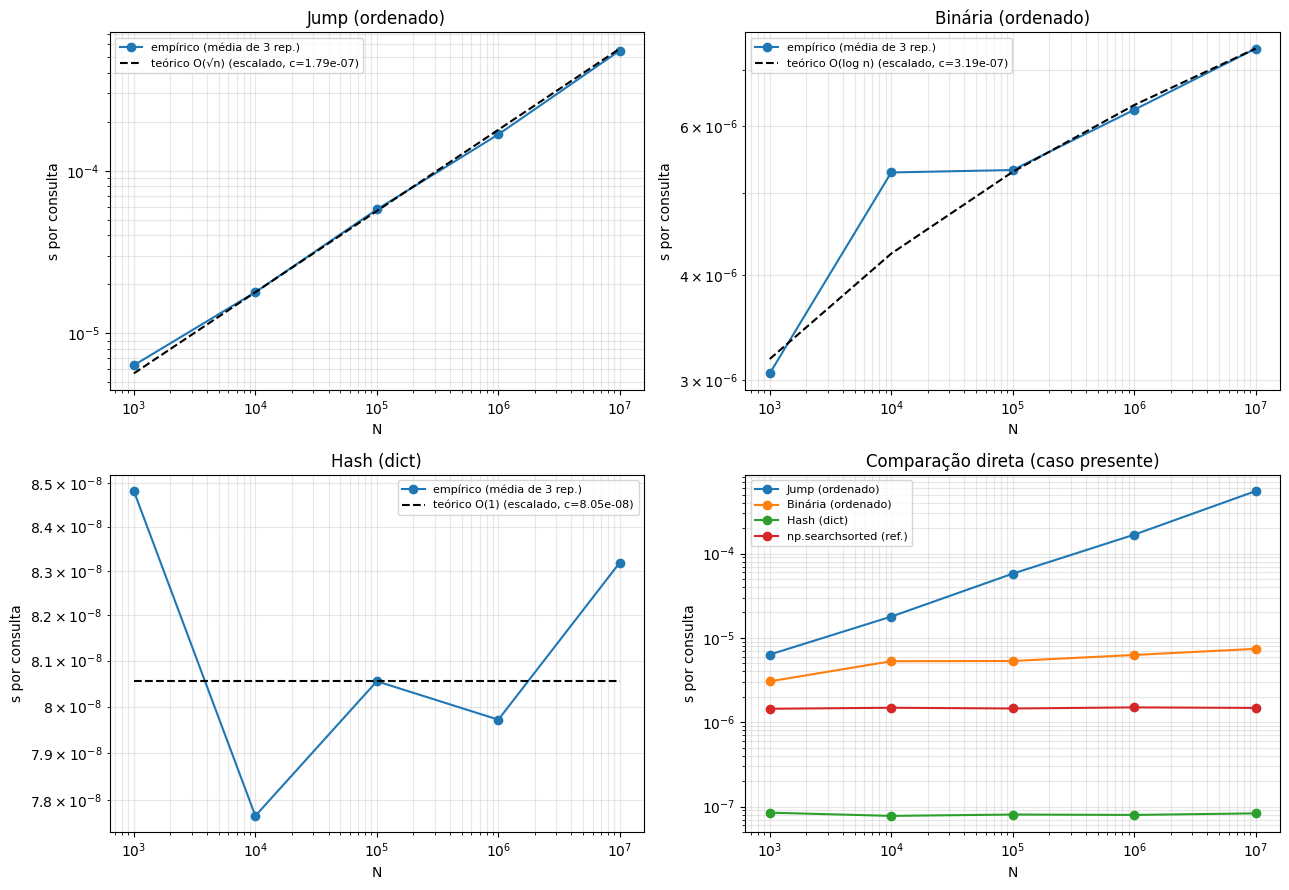

algoritmo,Binária (ordenado),Hash (dict),Jump (ordenado)
N,,,
1000,0.96,1.05,1.12
10000,1.25,0.96,1.00
100000,1.00,1.00,1.02
1000000,0.99,0.99,0.94
10000000,1.00,1.03,0.97


In [10]:
teoria = {"Jump (ordenado)": ("O(√n)", lambda n: np.sqrt(n)),
          "Binária (ordenado)": ("O(log n)", lambda n: np.log2(n)),
          "Hash (dict)": ("O(1)", lambda n: np.ones_like(n, dtype=float))}
pres = tabela_hash[tabela_hash.caso == "presente"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9)); axes = axes.ravel()
razoes = []
for ax, (alg, (rotulo, f)) in zip(axes, teoria.items()):
    d = pres[pres.algoritmo == alg].sort_values("N")
    n = d.N.to_numpy(dtype=float); t = d.tempo_por_consulta_s.to_numpy()
    c = float(np.median(t / f(n)))
    ax.plot(n, t, "o-", label="empírico (média de 3 rep.)")
    ax.plot(n, c * f(n), "k--", label=f"teórico {rotulo} (escalado, c={c:.3g})")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(True, which="both", alpha=.3)
    ax.set_title(alg); ax.set_xlabel("N"); ax.set_ylabel("s por consulta"); ax.legend(fontsize=8)
    razoes.append(pd.DataFrame({"algoritmo": alg, "N": d.N.values, "t_medido/t_teorico": t / (c * f(n))}))
ax = axes[3]
for alg in pres.algoritmo.unique():
    d = pres[pres.algoritmo == alg].sort_values("N"); ax.plot(d.N, d.tempo_por_consulta_s, "o-", label=alg)
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(True, which="both", alpha=.3)
ax.set_title("Comparação direta (caso presente)"); ax.set_xlabel("N"); ax.set_ylabel("s por consulta"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{SAIDA}/grafico_teorico_vs_empirico.png", dpi=150, bbox_inches="tight"); plt.show()
tabela_razao = pd.concat(razoes)
display(tabela_razao.pivot(index="N", columns="algoritmo", values="t_medido/t_teorico").style.format("{:.2f}"))

## Custo amortizado (1 × 10.000 buscas) e ponto de equilíbrio

Para `Q` consultas num conjunto **estático**:

`C_jump(Q) = T_sort + Q·T_jump`  ·  `C_bin(Q) = T_sort + Q·T_bin`  ·  `C_hash(Q) = T_build + Q·T_hash`  ·  `C_seq(Q) = Q·T_seq`

A estratégia A passa a custar **menos** que a B para `Q > (fixo_A − fixo_B) / (var_B − var_A)` (quando `var_A < var_B` e `fixo_A > fixo_B`). Os tempos por consulta são os do **caso presente** (média). Os totais são **projeções** dos tempos medidos, não cronometragens de 10.000 consultas.

In [11]:
def custo(fixo, var, Q): return fixo + var * Q

def q_equilibrio(fixo_a, var_a, fixo_b, var_b):
    """Menor Q inteiro em que A custa MENOS que B. None se A nunca passa a B (var_a >= var_b)."""
    if var_a >= var_b:
        return None
    if fixo_a <= fixo_b:
        return 1
    return int(math.floor((fixo_a - fixo_b) / (var_b - var_a))) + 1

def t_q(N, nome):
    return float(pres[(pres.N == N) & (pres.algoritmo == nome)].tempo_por_consulta_s.iloc[0])

linhas_a, linhas_q = [], []
for _, r in tabela_fixos.iterrows():
    N = int(r.N); Ts, Tb = r.T_ordenacao_s, r.T_construcao_hash_s
    est = {"Jump + ordenação": (Ts, t_q(N, "Jump (ordenado)")),
           "Binária + ordenação": (Ts, t_q(N, "Binária (ordenado)")),
           "Hash + construção": (Tb, t_q(N, "Hash (dict)")),
           "np.searchsorted + ordenação (ref.)": (Ts, t_q(N, "np.searchsorted (ref.)"))}
    # Sequencial (sem custo fixo), se foi medida neste N na Etapa 2
    if len(tabela_spark):
        s = tabela_spark[(tabela_spark.N == N) & (tabela_spark.algoritmo == "Sequencial") & (tabela_spark.caso == "presente")]
        if len(s) and not np.isnan(s.tempo_medio_s.iloc[0]):
            est["Sequencial (sem custo fixo)"] = (0.0, float(s.tempo_medio_s.iloc[0]))
    for nome, (fixo, var) in est.items():
        linhas_a.append(dict(N=N, estrategia=nome, custo_fixo_s=fixo, tempo_por_consulta_s=var,
                             total_Q1_s=custo(fixo, var, 1), total_Q10000_s=custo(fixo, var, 10_000),
                             amortizado_Q10000_s=custo(fixo, var, 10_000) / 10_000))
    for a, b in (("Hash + construção", "Binária + ordenação"), ("Hash + construção", "Jump + ordenação"),
                 ("Binária + ordenação", "Jump + ordenação")):
        linhas_q.append(dict(N=N, A=a, B=b, Q_minimo_em_que_A_vence=q_equilibrio(*est[a], *est[b])))
    if "Sequencial (sem custo fixo)" in est:
        for a in ("Binária + ordenação", "Hash + construção"):
            linhas_q.append(dict(N=N, A=a, B="Sequencial (sem custo fixo)",
                                 Q_minimo_em_que_A_vence=q_equilibrio(*est[a], *est["Sequencial (sem custo fixo)"])))

tabela_amort = pd.DataFrame(linhas_a)
tabela_eq = pd.DataFrame(linhas_q)
tabela_amort.to_csv(f"{SAIDA}/amortizacao.csv", index=False)
tabela_eq.to_csv(f"{SAIDA}/ponto_equilibrio.csv", index=False)
display(tabela_amort.style.format({"custo_fixo_s": "{:.4g}", "tempo_por_consulta_s": "{:.3g}", "total_Q1_s": "{:.4g}",
                                   "total_Q10000_s": "{:.4g}", "amortizado_Q10000_s": "{:.3g}"}))
print("Q_minimo_em_que_A_vence = menor nº de consultas a partir do qual A custa MENOS que B (None = nunca, var_A >= var_B)")
display(tabela_eq)

,N,estrategia,custo_fixo_s,tempo_por_consulta_s,total_Q1_s,total_Q10000_s,amortizado_Q10000_s
0,1000,Jump + ordenação,0.0006186,6.34e-06,0.000625,0.06407,6.41e-06
1,1000,Binária + ordenação,0.0006186,3.06e-06,0.0006217,0.03118,3.12e-06
2,1000,Hash + construção,0.0001274,8.48e-08,0.0001275,0.0009755,9.76e-08
3,1000,np.searchsorted + ordenação (ref.),0.0006186,1.45e-06,0.0006201,0.01508,1.51e-06
4,10000,Jump + ordenação,0.0001125,1.79e-05,0.0001303,0.1789,1.79e-05
5,10000,Binária + ordenação,0.0001125,5.29e-06,0.0001178,0.05299,5.3e-06
6,10000,Hash + construção,0.000918,7.77e-08,0.0009181,0.001695,1.69e-07
7,10000,np.searchsorted + ordenação (ref.),0.0001125,1.49e-06,0.0001139,0.01497,1.5e-06
8,100000,Jump + ordenação,0.001182,5.77e-05,0.001239,0.5785,5.79e-05
9,100000,Binária + ordenação,0.001182,5.32e-06,0.001187,0.05441,5.44e-06


Q_minimo_em_que_A_vence = menor nº de consultas a partir do qual A custa MENOS que B (None = nunca, var_A >= var_B)


,N,A,B,Q_minimo_em_que_A_vence
0,1000,Hash + construção,Binária + ordenação,1
1,1000,Hash + construção,Jump + ordenação,1
2,1000,Binária + ordenação,Jump + ordenação,1
3,10000,Hash + construção,Binária + ordenação,155
4,10000,Hash + construção,Jump + ordenação,46
5,10000,Binária + ordenação,Jump + ordenação,1
6,100000,Hash + construção,Binária + ordenação,1705
7,100000,Hash + construção,Jump + ordenação,156
8,100000,Binária + ordenação,Jump + ordenação,1
9,1000000,Hash + construção,Binária + ordenação,22024


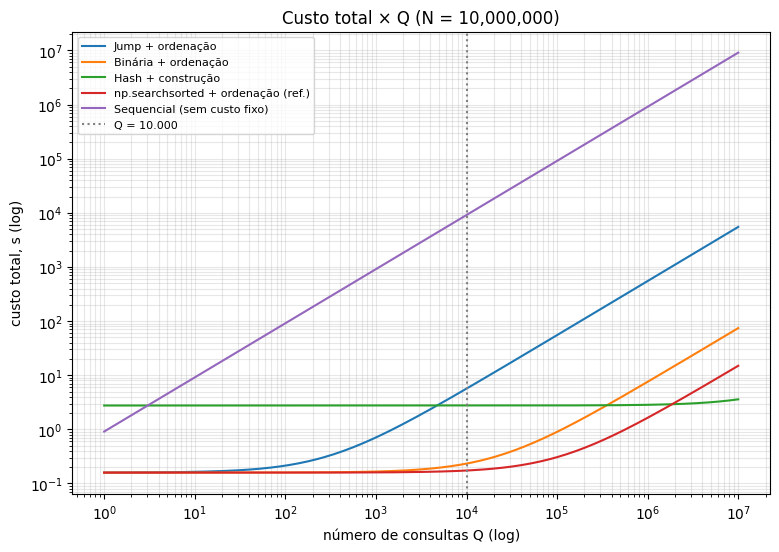

In [12]:
# Custo total × número de consultas, para o maior N medido (curvas se cruzam no ponto de equilíbrio)
Nmax = int(tabela_fixos.N.max())
a = tabela_amort[tabela_amort.N == Nmax]
Qs = np.logspace(0, 7, 200)
fig, ax = plt.subplots(figsize=(9, 6))
for _, r in a.iterrows():
    ax.plot(Qs, r.custo_fixo_s + r.tempo_por_consulta_s * Qs, label=r.estrategia)
ax.axvline(10_000, color="gray", ls=":", label="Q = 10.000")
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(True, which="both", alpha=.3)
ax.set_xlabel("número de consultas Q (log)"); ax.set_ylabel("custo total, s (log)")
ax.set_title(f"Custo total × Q (N = {Nmax:,})"); ax.legend(fontsize=8)
plt.savefig(f"{SAIDA}/grafico_custo_amortizado.png", dpi=150, bbox_inches="tight"); plt.show()

### Novos pedidos todo dia: custo de inserção (o que o cenário da Etapa 5 exige)

O enunciado descreve um sistema que **recebe pedidos novos diariamente**. Um conjunto estático ignora isso. Aqui se mede:
- inserção no `dict` (O(1) amortizado);
- inserção **imediata** num vetor ordenado (`np.insert`, O(N) por inserção, porque copia o vetor);
- **reordenação em lote** uma vez por dia (os pedidos novos só ficam buscáveis depois dela).

O modelo diário compara os custos com `I` inserções e `Q` consultas por dia, usando os tempos medidos neste mesmo N.

In [13]:
N_INS = 10**5 if MODO_TESTE else 10**6
arr = rng.permutation(N_INS).astype(np.int64); ordenado = np.sort(arr)
indice = dict(zip(arr.tolist(), range(N_INS)))
K_HASH, K_SORTED = 10_000, 20
novos = (N_INS + np.arange(1, K_HASH + 1)).tolist()

ts = []
for _ in range(REPETICOES):                                   # cópia fora da cronometragem
    d2 = dict(indice); t0 = time.perf_counter()
    for k in novos: d2[k] = k
    ts.append((time.perf_counter() - t0) / K_HASH)
t_ins_hash = float(np.mean(ts))

ts = []
for _ in range(REPETICOES):
    v = ordenado.copy(); t0 = time.perf_counter()
    for k in novos[:K_SORTED]:
        v = np.insert(v, np.searchsorted(v, k), k)
    ts.append((time.perf_counter() - t0) / K_SORTED)
t_ins_sorted = float(np.mean(ts))

def t_reordenar_lote(I):
    lote = (N_INS + np.arange(1, I + 1)).astype(np.int64)
    ts = timeit.repeat(lambda: np.sort(np.concatenate([ordenado, lote])), number=1, repeat=REPETICOES)
    return float(np.mean(ts))

t_hash_q, t_bin_q = t_q(N_INS, "Hash (dict)"), t_q(N_INS, "Binária (ordenado)")
print(f"N = {N_INS:,} | inserir no dict: {t_ins_hash:.3g} s | inserir no ordenado (np.insert): {t_ins_sorted:.3g} s")

linhas_d = []
for I in (10**3, 10**4, 10**5):
    T_re = t_reordenar_lote(I)
    for Q in (10**4, 10**5, 10**6, 10**7):
        linhas_d.append(dict(inserts_dia=I, consultas_dia=Q,
                             hash_s=I * t_ins_hash + Q * t_hash_q,
                             ordenado_insere_cada_pedido_s=I * t_ins_sorted + Q * t_bin_q,
                             ordenado_reordena_1x_dia_s=T_re + Q * t_bin_q))
modelo_diario = pd.DataFrame(linhas_d)
modelo_diario.to_csv(f"{SAIDA}/modelo_diario.csv", index=False)
display(modelo_diario.style.format({c: "{:.4g}" for c in modelo_diario.columns[2:]}))
del arr, ordenado, indice; gc.collect()

N = 1,000,000 | inserir no dict: 8.25e-08 s | inserir no ordenado (np.insert): 0.000557 s


,inserts_dia,consultas_dia,hash_s,ordenado_insere_cada_pedido_s,ordenado_reordena_1x_dia_s
0,1000,10000,0.0008797,0.6202,0.07672
1,1000,100000,0.008054,1.185,0.6414
2,1000,1000000,0.0798,6.832,6.289
3,1000,10000000,0.7972,63.3,62.76
4,10000,10000,0.001622,5.637,0.07696
5,10000,100000,0.008797,6.202,0.6417
6,10000,1000000,0.08054,11.85,6.289
7,10000,10000000,0.798,68.32,62.76
8,100000,10000,0.009047,55.8,0.0782
9,100000,100000,0.01622,56.37,0.6429


4823

## Etapa 4 — Dados reais e sujos: qualidade das chaves e pipeline ETL

Base: qualquer CSV com uma coluna de chave (no trabalho: `dados_vendas_sujos.csv`, coluna `ID_Pedido`). **Para outro projeto, basta rodar a célula seguinte e enviar o CSV**; o notebook acha a coluna de chave sozinho (ou use `COLUNA_CHAVE_MANUAL`). A leitura é feita **tudo como texto** (`dtype=str`), para que nenhuma conversão automática esconda o problema. **Nenhum tratamento é assumido antes de olhar os dados:** primeiro o perfil, depois as correções, e cada uma é registrada (o quê, quanto, por quê).

> **Antes de rodar o pipeline, leia o perfil.** Se o perfil mostrar um padrão de sujeira que os passos abaixo não cobrem (separadores diferentes, zeros à esquerda, prefixos), acrescente o passo **e registre-o** no log de tratamentos.

In [14]:
# ============================================================
# CONFIGURAÇÃO — para OUTRO projeto, normalmente não precisa mexer em nada:
# basta rodar a célula e enviar o CSV quando o Colab pedir.
# ============================================================
ARQUIVO_CSV = None            # ex.: "meus_dados.csv". None = detectar sozinho (ou pedir upload)
COLUNA_CHAVE_MANUAL = None    # ex.: "ID_Cliente". None = detectar sozinho
FORCAR_UPLOAD = False         # True = sempre abrir a janela de envio (use ao trocar de projeto)
COLUNA_CHAVE = "ID_Pedido"    # coluna preferida (a do trabalho); usada só se existir

import glob
IGNORAR_NOMES = ("rejeitados", "base_limpa", "log_tratamentos", "antes_depois", "tabela_", "custos_", "amortizacao",
                 "ponto_equilibrio", "modelo_diario", "verificacao")

def localizar_csv():
    if ARQUIVO_CSV:
        assert os.path.exists(ARQUIVO_CSV), f"{ARQUIVO_CSV} não encontrado"
        return ARQUIVO_CSV
    if not FORCAR_UPLOAD:
        achados = [p for d in (".", "/content") if os.path.isdir(d) for p in glob.glob(os.path.join(d, "*.csv"))
                   if not any(n in os.path.basename(p) for n in IGNORAR_NOMES)]
        achados = sorted(set(os.path.abspath(p) for p in achados), key=os.path.getmtime, reverse=True)
        if achados:
            if len(achados) > 1:
                print("Vários CSV encontrados; usando o mais recente. Para outro, defina ARQUIVO_CSV:")
                for p in achados: print("   -", p)
            return achados[0]
    if "google.colab" in sys.modules:
        from google.colab import files
        print("Selecione o arquivo CSV do projeto")
        enviados = files.upload()
        if enviados:
            return next(iter(enviados))          # nome real do arquivo enviado (o Colab pode renomear)
    return None

def detectar_coluna_chave(colunas):
    if COLUNA_CHAVE_MANUAL:
        achada = next((c for c in colunas if c.lower() == COLUNA_CHAVE_MANUAL.lower()), None)
        assert achada, f"COLUNA_CHAVE_MANUAL={COLUNA_CHAVE_MANUAL!r} não existe. Colunas: {list(colunas)}"
        return achada
    exata = next((c for c in colunas if c.lower() == COLUNA_CHAVE.lower()), None)
    if exata:
        return exata
    for palavra in ("pedido", "id", "chave", "key", "codigo", "código", "cod", "numero", "número", "num"):
        c = next((c for c in colunas if palavra in c.lower()), None)
        if c:
            print(f"Coluna de chave detectada: {c!r} (por conter {palavra!r}). Se estiver errada, defina COLUNA_CHAVE_MANUAL.")
            return c
    print(f"ATENÇÃO: nenhuma coluna parece chave; usando a primeira ({colunas[0]!r}). Defina COLUNA_CHAVE_MANUAL.")
    return colunas[0]

def gerar_csv_sintetico_para_teste(caminho):
    # SOMENTE para validar o código em MODO_TESTE. Não é a base real.
    linhas = [("PED-%04d" % i, f"cliente{i%17}", "%.2f" % (10 + i * 1.5)) for i in range(1, 201)]
    linhas[3] = (" " + linhas[3][0], *linhas[3][1:])                  # espaço na ponta
    linhas[5] = (linhas[5][0].lower(), *linhas[5][1:])                # caixa diferente
    linhas[7] = (linhas[7][0] + "\u00a0", *linhas[7][1:])             # espaço não separável
    linhas += [linhas[10], linhas[11]]                                # duplicatas exatas
    linhas.append((linhas[20][0], "outro_cliente", "999.99"))         # chave igual, conteúdo diferente
    linhas.append(("", "sem_chave", "1.00"))                          # chave vazia
    linhas.append(("XYZ", "formato_estranho", "2.00"))                # formato fora do padrão
    pd.DataFrame(linhas, columns=[COLUNA_CHAVE, "Cliente", "Valor"]).to_csv(caminho, index=False)

CAMINHO_CSV = localizar_csv()
if CAMINHO_CSV is None:
    if MODO_TESTE:
        CAMINHO_CSV = "dados_sinteticos_TESTE.csv"; gerar_csv_sintetico_para_teste(CAMINHO_CSV)
        print("*** USANDO BASE SINTÉTICA DE TESTE (não é a base real) ***")
    else:
        raise FileNotFoundError("Nenhum CSV encontrado. Rode a célula de novo e envie o arquivo (ou use o ícone de pasta > upload).")

def ler_csv(caminho):
    for enc in ("utf-8-sig", "latin-1"):
        try:
            df = pd.read_csv(caminho, dtype=str, keep_default_na=False, sep=None, engine="python", encoding=enc)
            return df, enc
        except UnicodeDecodeError:
            continue
    raise ValueError("Não foi possível decodificar o CSV")

bruto, codificacao = ler_csv(CAMINHO_CSV)
bruto.columns = [c.strip() for c in bruto.columns]
col = detectar_coluna_chave(list(bruto.columns))
bruto["linha_original"] = np.arange(len(bruto)) + 2          # 1 = cabeçalho
print(f"Arquivo: {CAMINHO_CSV} | codificação: {codificacao} | linhas: {len(bruto):,} | coluna de chave: {col!r}")
print("Colunas:", list(bruto.columns))
bruto.head(10)

Selecione o arquivo CSV do projeto


Saving dados_vendas_sujos_SIMULADO (1).csv to dados_vendas_sujos_SIMULADO (1).csv
Arquivo: dados_vendas_sujos_SIMULADO (1).csv | codificação: utf-8-sig | linhas: 5,070 | coluna de chave: 'ID_Pedido'
Colunas: ['ID_Pedido', 'Data', 'Cliente', 'Produto', 'Quantidade', 'Valor_Unitario', 'Valor_Total', 'Cidade', 'linha_original']


,ID_Pedido,Data,Cliente,Produto,Quantidade,Valor_Unitario,Valor_Total,Cidade,linha_original
0,PED-04701,19/06/2026,Cliente 165,Cabo blindado,3,38.90,116.70,Foz do Iguaçu,2
1,PED-03624,08/03/2026,Cliente 191,Fonte 12V,9,72.00,648.00,Cascavel,3
2,PED-03341,12/03/2026,Cliente 291,Balança 30kg,9,560.00,5040.00,Maringá,4
3,PED-02270,16/11/2026,Cliente 047,Fonte 12V,10,72.00,720.00,Maringá,5
4,PED-00617,02/09/2026,Cliente 117,Balança 30kg,4,560.00,2240.00,Maringá,6
5,PED-03010,21/11/2026,Cliente 033,Fonte 12V,6,72.00,432.00,Maringá,7
6,PED-01628,19/09/2026,Cliente 077,Cabo blindado,2,38.90,77.80,Foz do Iguaçu,8
7,PED-02762,05/10/2026,Cliente 999,Fonte 12V,4,72.00,316.8,Cascavel,9
8,PED-00962,05/10/2026,Cliente 195,Balança 30kg,10,560.00,5600.00,Maringá,10
9,PED-02957,20/07/2026,Cliente 211,Indicador digital,9,690.00,6210.00,Chapecó,11


In [15]:
# ---------------- PERFIL DA COLUNA ANTES DE QUALQUER LIMPEZA ----------------
def assinatura(s):
    """Forma da chave: letras->A, dígitos->9, repetições colapsadas. Ex.: 'PED-0012' -> 'A-9'."""
    t = re.sub(r"[^\W\d_]", "A", s)
    t = re.sub(r"\d", "9", t)
    return re.sub(r"9+", "9", re.sub(r"A+", "A", t))

k = bruto[col]
perfil = {
    "linhas": len(bruto),
    "chaves vazias/brancas": int((k.str.strip() == "").sum()),
    "com espaço nas pontas": int((k != k.str.strip()).sum()),
    "com espaço interno": int(k.str.strip().str.contains(r"\s").sum()),
    "com caractere não imprimível/NBSP": int(k.str.contains(r"[\u00a0\u200b\t\r\n]").sum()),
    "caixa mista (difere de maiúsculas)": int((k != k.str.upper()).sum()),
    "chaves distintas (texto cru)": int(k.nunique()),
    "linhas com chave repetida (texto cru)": int(k.duplicated(keep=False).sum()),
}
display(pd.Series(perfil, name="valor").to_frame())
print("Formatos (assinaturas) mais frequentes no texto cru:")
display(k.map(assinatura).value_counts().head(10).to_frame("linhas"))

,valor
linhas,5070
chaves vazias/brancas,10
com espaço nas pontas,95
com espaço interno,0
com caractere não imprimível/NBSP,30
caixa mista (difere de maiúsculas),60
chaves distintas (texto cru),4974
linhas com chave repetida (texto cru),175


Formatos (assinaturas) mais frequentes no texto cru:


,linhas
ID_Pedido,
A-9,4948
A-9,33
A-9,30
A-9,27
A,8
9,6
,5
A/A,5
,5


### Casos em que a busca falha ou devolve o registro errado (ANTES de limpar)

Dois casos que o enunciado pede para mostrar, gerados a partir da própria base:
1. **Chave "visualmente igual", mas diferente no texto** (espaço, caixa): a busca pela chave canônica devolve `-1`, embora o pedido exista.
2. **Chave repetida:** o `dict` guarda **a última** linha, a Sequencial devolve **a primeira**: dois algoritmos, dois pedidos diferentes para a mesma chave. A Binária devolve uma qualquer entre as iguais.

In [16]:
chaves_cruas = bruto[col].to_numpy(dtype=object)
def canonica_simples(s): return re.sub(r"\s+", "", unicodedata.normalize("NFKC", s)).upper()

# ---- Caso 1: a chave canônica existe, mas a busca exata no texto cru não a encontra ----
casos_falha_1 = []
cru_set = set(chaves_cruas)
for pos, s in enumerate(chaves_cruas):
    c = canonica_simples(s)
    if c and c != s and c not in cru_set:
        casos_falha_1.append((pos, s, c))
    if len(casos_falha_1) >= 3: break
print("CASO 1 — busca exata pela chave canônica")
if casos_falha_1:
    ordem_cru = np.argsort(chaves_cruas, kind="stable"); ordenado_cru = chaves_cruas[ordem_cru]
    for pos, s, c in casos_falha_1:
        print(f"  linha {bruto.linha_original.iloc[pos]}: texto cru = {s!r}  | buscando {c!r}: "
              f"Sequencial -> {busca_sequencial(chaves_cruas, c)[0]}, Jump -> {jump_search(ordenado_cru, c)[0]}, "
              f"Binária -> {busca_binaria(ordenado_cru, c)[0]}, Hash -> {dict(zip(chaves_cruas, range(len(chaves_cruas)))).get(c, -1)}"
              "   (-1 = 'não existe', mas o pedido existe)")
else:
    print("  Nenhum caso encontrado nesta base (espaços/caixa). Veja o perfil acima para outro tipo de falha.")

# ---- Caso 2: chave repetida -> algoritmos diferentes devolvem registros diferentes ----
print("\nCASO 2 — chave repetida")
nulos_txt = {"", "NULL", "NAN", "NONE", "N/A", "NA", "-", "#N/D"}      # chave vazia repetida não é um bom exemplo
dups = bruto[bruto.duplicated(col, keep=False) & ~bruto[col].map(lambda x: canonica_simples(x) in nulos_txt)]
if len(dups):
    outras = [c for c in bruto.columns if c not in (col, "linha_original")]
    conflitantes = [k_ for k_, g in dups.groupby(col) if len(g.drop_duplicates(subset=outras)) > 1]
    chave_dup = conflitantes[0] if conflitantes else dups[col].iloc[0]   # prefere conteúdo diferente
    print("  (escolhida uma chave com conteúdo DIFERENTE entre as linhas)" if conflitantes
          else "  (só há duplicatas exatas nesta base; o registro devolvido é igual, mas a chave perde linhas no dict)")
    hash_cru = {}
    for i, s in enumerate(chaves_cruas): hash_cru[s] = i           # dict sobrescreve em silêncio: fica a ÚLTIMA
    ordem_cru = np.argsort(chaves_cruas, kind="stable"); ordenado_cru = chaves_cruas[ordem_cru]
    i_seq = busca_sequencial(chaves_cruas, chave_dup)[0]
    i_bin = int(ordem_cru[busca_binaria(ordenado_cru, chave_dup)[0]])
    i_hash = hash_cru[chave_dup]
    print(f"  chave {chave_dup!r} aparece em {len(dups[dups[col]==chave_dup])} linhas")
    print(f"  Sequencial -> linha {bruto.linha_original.iloc[i_seq]} | Binária -> linha {bruto.linha_original.iloc[i_bin]} "
          f"| Hash -> linha {bruto.linha_original.iloc[i_hash]}")
    display(bruto[bruto[col] == chave_dup])
    print(f"  O dict tem {len(hash_cru):,} entradas para {len(chaves_cruas):,} linhas: "
          f"{len(chaves_cruas) - len(hash_cru):,} registros ficaram invisíveis, sem erro nem aviso.")
else:
    print("  Nenhuma chave repetida no texto cru (podem aparecer só depois de normalizar).")

CASO 1 — busca exata pela chave canônica
  linha 17: texto cru = 'PED-01287\xa0'  | buscando 'PED-01287': Sequencial -> -1, Jump -> -1, Binária -> -1, Hash -> -1   (-1 = 'não existe', mas o pedido existe)
  linha 62: texto cru = 'ped-00501'  | buscando 'PED-00501': Sequencial -> -1, Jump -> -1, Binária -> -1, Hash -> -1   (-1 = 'não existe', mas o pedido existe)
  linha 67: texto cru = ' PED-04171'  | buscando 'PED-04171': Sequencial -> -1, Jump -> -1, Binária -> -1, Hash -> -1   (-1 = 'não existe', mas o pedido existe)

CASO 2 — chave repetida
  (escolhida uma chave com conteúdo DIFERENTE entre as linhas)
  chave '123' aparece em 3 linhas
  Sequencial -> linha 2257 | Binária -> linha 2257 | Hash -> linha 3128


,ID_Pedido,Data,Cliente,Produto,Quantidade,Valor_Unitario,Valor_Total,Cidade,linha_original
2255,123,12/07/2026,Cliente 191,Indicador digital,6,690.00,4140.00,Foz do Iguaçu,2257
3023,123,05/10/2026,Cliente 253,Fonte 12V,1,72.00,72.00,Cascavel,3025
3126,123,30/03/2026,Cliente 103,Fonte 12V,3,72.00,216.00,Foz do Iguaçu,3128


  O dict tem 4,974 entradas para 5,070 linhas: 96 registros ficaram invisíveis, sem erro nem aviso.


### Pipeline ETL

**Extract** (já feito, tudo como texto) → **Transform** (normalizar a chave) → **Validate** (formato) → **Reject** (nulas, formato inconsistente, duplicadas) → **Load** (base limpa).

Decisões de projeto (justifique-as no relatório):
- **Duplicata exata** (mesma chave **e** mesmo conteúdo em todas as colunas): mantém-se a primeira linha; as demais vão para os rejeitados, e nada de informação se perde.
- **Duplicata conflitante** (mesma chave, conteúdo diferente): **todas** as linhas do grupo vão para os rejeitados. Escolher uma delas seria adivinhar qual pedido é o verdadeiro; isso é decisão de negócio, não do pipeline.
- **Formato:** a validação usa a assinatura dominante da base normalizada (ou `REGEX_VALIDA`, se você definir uma). Se a assinatura dominante cobrir uma fração baixa das linhas, o pipeline avisa: nesse caso **defina a regra manualmente** após olhar o perfil.
- **Rastreabilidade:** cada linha rejeitada leva `linha_original` e `motivo`. Invariante verificado: `entrada = limpas + rejeitadas`.

In [17]:
REMOVER_ESPACOS_INTERNOS = True     # 'PED 001' -> 'PED001'. Desative se espaço interno fizer parte do padrão real.
TOKENS_NULOS = {"NAN", "NULL", "NONE", "N/A", "NA", "-", "#N/D"}
REGEX_VALIDA = None                 # ex.: r"^PED-\d{4}$". None = inferir pela assinatura dominante

def normalizar_chaves(serie):
    """Normaliza a chave aplicando passos em sequência e contando quantas chaves cada passo alterou."""
    log = []
    s0 = serie.astype(str)
    s1 = s0.map(lambda x: unicodedata.normalize("NFKC", x).replace("\u200b", "").replace("\u00a0", " "))
    log.append(("Normalizar Unicode (NFKC), NBSP e espaço de largura zero", int((s1 != s0).sum()),
                "caracteres invisíveis fazem chaves iguais ao olho serem diferentes para o computador"))
    s2 = s1.str.strip()
    log.append(("Remover espaços nas pontas", int((s2 != s1).sum()), "espaço nas pontas quebra a comparação exata"))
    if REMOVER_ESPACOS_INTERNOS:
        s3 = s2.str.replace(r"\s+", "", regex=True)
        log.append(("Remover espaços internos", int((s3 != s2).sum()), "padroniza chaves digitadas com espaços"))
    else:
        s3 = s2
    s4 = s3.str.upper()
    log.append(("Padronizar para maiúsculas", int((s4 != s3).sum()), "'ped-1' e 'PED-1' são a mesma chave de negócio"))
    eh_nula = s4.eq("") | s4.isin(TOKENS_NULOS)
    return s4.where(~eh_nula, None), log

def pipeline_etl(bruto, col):
    colunas_dado = [c for c in bruto.columns if c not in ("linha_original",)]
    df = bruto.copy()
    log = []
    df["chave_original"] = df[col]
    df["chave_norm"], passos = normalizar_chaves(df[col])
    for etapa, quanto, porque in passos:
        log.append(dict(etapa="Transformar", o_que=etapa, quanto=quanto, por_que=porque))

    rej = []
    # 1) chaves nulas
    m = df.chave_norm.isna()
    rej.append(df[m].assign(motivo="chave_nula"))
    log.append(dict(etapa="Rejeitar", o_que="Chave nula/vazia", quanto=int(m.sum()), por_que="sem chave não há busca possível"))
    df = df[~m]

    # 2) formato inconsistente
    sig = df.chave_norm.map(assinatura)
    if REGEX_VALIDA:
        valido = df.chave_norm.str.match(REGEX_VALIDA)
        regra = f"regex {REGEX_VALIDA}"
    else:
        dominante, freq = sig.value_counts().index[0], sig.value_counts().iloc[0] / max(len(sig), 1)
        valido = sig.eq(dominante); regra = f"assinatura dominante {dominante!r} ({freq:.1%} das linhas)"
        if freq < 0.5:
            print(f"ATENÇÃO: a assinatura dominante cobre só {freq:.1%} das chaves; defina REGEX_VALIDA manualmente.")
    rej.append(df[~valido].assign(motivo="formato_inconsistente"))
    log.append(dict(etapa="Rejeitar", o_que=f"Formato fora do padrão ({regra})", quanto=int((~valido).sum()),
                    por_que="chave fora do padrão do sistema é suspeita de erro de digitação/origem"))
    df = df[valido]

    # 3) duplicatas exatas: mantém a primeira
    cols_conteudo = ["chave_norm"] + [c for c in colunas_dado if c != col]
    exata = df.duplicated(subset=cols_conteudo, keep="first")
    rej.append(df[exata].assign(motivo="duplicata_exata"))
    log.append(dict(etapa="Rejeitar", o_que="Duplicata exata (mesma chave e mesmo conteúdo)", quanto=int(exata.sum()),
                    por_que="repetição sem informação nova; mantém-se a primeira ocorrência"))
    df = df[~exata]

    # 4) duplicatas conflitantes: rejeita o grupo inteiro
    conf = df.duplicated(subset="chave_norm", keep=False)
    rej.append(df[conf].assign(motivo="chave_duplicada_conflitante"))
    log.append(dict(etapa="Rejeitar", o_que="Chave repetida com conteúdo diferente (todas as linhas do grupo)",
                    quanto=int(conf.sum()), por_que="não há como saber qual registro é o verdadeiro; decisão de negócio"))
    df = df[~conf]

    limpa = df.drop(columns=[col]).rename(columns={"chave_norm": col}).drop(columns=["chave_original"])
    limpa = limpa[[col] + [c for c in limpa.columns if c != col]].reset_index(drop=True)
    rejeitados = pd.concat(rej)
    rejeitados = rejeitados.drop(columns=["chave_norm"]).rename(columns={"chave_original": f"{col}_original"})
    cols_rej = ["linha_original", "motivo", f"{col}_original"] + [c for c in rejeitados.columns
                                                               if c not in ("linha_original", "motivo", f"{col}_original", col)]
    return limpa, rejeitados[cols_rej].sort_values("linha_original").reset_index(drop=True), pd.DataFrame(log)

limpa, rejeitados, log_tratamentos = pipeline_etl(bruto, col)

# Invariante: nada se perde
assert len(bruto) == len(limpa) + len(rejeitados), (len(bruto), len(limpa), len(rejeitados))
assert limpa[col].is_unique and limpa[col].notna().all()
limpa.to_csv(f"{SAIDA}/base_limpa.csv", index=False)
rejeitados.to_csv(f"{SAIDA}/rejeitados_{col}.csv", index=False)
log_tratamentos.to_csv(f"{SAIDA}/log_tratamentos.csv", index=False)
print("Invariante OK: entrada = limpas + rejeitadas")
display(log_tratamentos)
display(rejeitados.motivo.value_counts().to_frame("linhas"))

Invariante OK: entrada = limpas + rejeitadas


,etapa,o_que,quanto,por_que
0,Transformar,"Normalizar Unicode (NFKC), NBSP e espaço de la...",30,caracteres invisíveis fazem chaves iguais ao o...
1,Transformar,Remover espaços nas pontas,95,espaço nas pontas quebra a comparação exata
2,Transformar,Remover espaços internos,0,padroniza chaves digitadas com espaços
3,Transformar,Padronizar para maiúsculas,60,'ped-1' e 'PED-1' são a mesma chave de negócio
4,Rejeitar,Chave nula/vazia,20,sem chave não há busca possível
5,Rejeitar,Formato fora do padrão (assinatura dominante '...,12,chave fora do padrão do sistema é suspeita de ...
6,Rejeitar,Duplicata exata (mesma chave e mesmo conteúdo),40,repetição sem informação nova; mantém-se a pri...
7,Rejeitar,Chave repetida com conteúdo diferente (todas a...,63,não há como saber qual registro é o verdadeiro...


,linhas
motivo,
chave_duplicada_conflitante,63
duplicata_exata,40
chave_nula,20
formato_inconsistente,12


In [18]:
# ---------------- ANTES × DEPOIS ----------------
antes_dep = pd.DataFrame({
    "métrica": ["linhas", "chaves nulas/vazias", "chaves distintas", "linhas com chave repetida", "linhas rejeitadas"],
    "antes (bruto)": [len(bruto), int((bruto[col].str.strip() == "").sum()), int(bruto[col].nunique()),
                      int(bruto[col].duplicated(keep=False).sum()), 0],
    "depois (limpa)": [len(limpa), 0, int(limpa[col].nunique()), int(limpa[col].duplicated(keep=False).sum()), len(rejeitados)],
})
antes_dep.to_csv(f"{SAIDA}/antes_depois.csv", index=False)
display(antes_dep)

# ---------------- BUSCAS NA BASE LIMPA: todas devem devolver o registro correto ----------------
chaves = limpa[col].to_numpy(dtype=object)
ordem = np.argsort(chaves, kind="stable"); ordenado = chaves[ordem]
indice_hash = {c: i for i, c in enumerate(chaves)}
assert len(indice_hash) == len(chaves)                       # agora o dict não perde nenhum registro

amostra_seq = rng.choice(len(chaves), size=min(200, len(chaves)), replace=False)   # Sequencial é O(N) por busca
resultados = {"Sequencial": 0, "Jump": 0, "Binária": 0, "Hash": 0}
for i, c in enumerate(chaves):
    assert ordem[jump_search(ordenado, c)[0]] == i;  resultados["Jump"] += 1
    assert ordem[busca_binaria(ordenado, c)[0]] == i; resultados["Binária"] += 1
    assert indice_hash[c] == i;                       resultados["Hash"] += 1
for i in amostra_seq:
    assert busca_sequencial(chaves, chaves[i])[0] == i; resultados["Sequencial"] += 1
for c in ("ZZZ-INEXISTENTE", "000"):                          # chaves ausentes
    assert busca_sequencial(chaves, c)[0] == -1 and jump_search(ordenado, c)[0] == -1
    assert busca_binaria(ordenado, c)[0] == -1 and c not in indice_hash
verif = pd.DataFrame({"algoritmo": list(resultados), "buscas_corretas": list(resultados.values()),
                      "total_de_chaves_limpas": len(chaves)})
verif.to_csv(f"{SAIDA}/verificacao_pos_limpeza.csv", index=False)
print("Todas as buscas devolveram o registro correto (assert aprovado). Sequencial verificada numa amostra de 200 chaves, por custo O(N).")
display(verif)

,métrica,antes (bruto),depois (limpa)
0,linhas,5070,4935
1,chaves nulas/vazias,10,0
2,chaves distintas,4974,4935
3,linhas com chave repetida,175,0
4,linhas rejeitadas,0,135


Todas as buscas devolveram o registro correto (assert aprovado). Sequencial verificada numa amostra de 200 chaves, por custo O(N).


,algoritmo,buscas_corretas,total_de_chaves_limpas
0,Sequencial,200,4935
1,Jump,4935,4935
2,Binária,4935,4935
3,Hash,4935,4935


## Etapa 5 — Recomendação ao gestor de TI

Esta célula **reúne os números medidos** para você escrever a recomendação (Seção 6 do relatório). A decisão em si precisa sair dos seus dados: o notebook não a escreve por você.

Perguntas que a recomendação precisa responder com os números abaixo:
1. Em 10.000 consultas, qual estratégia custa menos no total (custo amortizado)? E em 1 consulta?
2. A partir de quantas consultas o hash compensa o custo de construção? O volume real de consultas do sistema fica acima ou abaixo desse ponto?
3. Com pedidos novos todo dia, quanto custa manter cada estrutura atualizada (modelo diário)?
4. O que acontece quando os dados passam da RAM? (Etapa 2: só o Spark responde. Mas o Spark paga custo fixo por consulta.)
5. O que a qualidade das chaves mudou? Quantos registros ficaram invisíveis ou errados antes da limpeza?

**Limites do experimento a declarar:** Colab (uma máquina); Spark em `local[*]` (não é cluster) e `spark.range` (não lê dados de disco); implementações em Python puro para Sequencial/Jump/Binária (constantes de implementação, não só algoritmo); chaves inteiras sintéticas nas Etapas 2–3; Sequencial medida com poucos alvos em N grande; custos amortizados são projeções dos tempos medidos.

In [19]:
# ---------------- PAINEL DE DECISÃO (números para o relatório) ----------------
Nmax = int(tabela_fixos.N.max())
print(f"=== N = {Nmax:,} ===")
display(tabela_amort[tabela_amort.N == Nmax].set_index("estrategia")[
    ["custo_fixo_s", "tempo_por_consulta_s", "total_Q1_s", "total_Q10000_s"]].style.format("{:.4g}"))
print("Ponto de equilíbrio (menor Q em que A custa menos que B):")
display(tabela_eq[tabela_eq.N == Nmax])
print(f"=== Modelo diário (N = {N_INS:,}) ===")
display(modelo_diario.style.format({c: "{:.4g}" for c in modelo_diario.columns[2:]}))
print("=== Qualidade das chaves ===")
display(antes_dep)
print("=== Spark × parte 1 ===")
if len(tabela_spark):
    display(tabela_spark[tabela_spark.caso != "-"].pivot_table(index="N", columns=["algoritmo", "caso"],
                                                                 values="tempo_medio_s").style.format("{:.4g}"))
if MODO_TESTE:
    print("\n*** MODO_TESTE: estes números NÃO valem para o relatório ***")

=== N = 10,000,000 ===


,custo_fixo_s,tempo_por_consulta_s,total_Q1_s,total_Q10000_s
estrategia,,,,
Jump + ordenação,0.1588,0.0005499,0.1594,5.658
Binária + ordenação,0.1588,7.416e-06,0.1588,0.233
Hash + construção,2.759,8.318e-08,2.759,2.759
np.searchsorted + ordenação (ref.),0.1588,1.48e-06,0.1588,0.1736
Sequencial (sem custo fixo),0,0.912,0.912,9120


Ponto de equilíbrio (menor Q em que A custa menos que B):


,N,A,B,Q_minimo_em_que_A_vence
14,10000000,Hash + construção,Binária + ordenação,354548
15,10000000,Hash + construção,Jump + ordenação,4729
16,10000000,Binária + ordenação,Jump + ordenação,1
17,10000000,Binária + ordenação,Sequencial (sem custo fixo),1
18,10000000,Hash + construção,Sequencial (sem custo fixo),4


=== Modelo diário (N = 1,000,000) ===


,inserts_dia,consultas_dia,hash_s,ordenado_insere_cada_pedido_s,ordenado_reordena_1x_dia_s
0,1000,10000,0.0008797,0.6202,0.07672
1,1000,100000,0.008054,1.185,0.6414
2,1000,1000000,0.0798,6.832,6.289
3,1000,10000000,0.7972,63.3,62.76
4,10000,10000,0.001622,5.637,0.07696
5,10000,100000,0.008797,6.202,0.6417
6,10000,1000000,0.08054,11.85,6.289
7,10000,10000000,0.798,68.32,62.76
8,100000,10000,0.009047,55.8,0.0782
9,100000,100000,0.01622,56.37,0.6429


=== Qualidade das chaves ===


,métrica,antes (bruto),depois (limpa)
0,linhas,5070,4935
1,chaves nulas/vazias,10,0
2,chaves distintas,4974,4935
3,linhas com chave repetida,175,0
4,linhas rejeitadas,0,135


=== Spark × parte 1 ===


In [20]:
# ---------------- Empacotar saídas e guardar o ambiente ----------------
with open(f"{SAIDA}/ambiente.json", "w", encoding="utf-8") as f:
    json.dump(AMBIENTE, f, indent=2, ensure_ascii=False)
import shutil
shutil.make_archive("saidas_parte2", "zip", SAIDA)
print("Arquivos gerados em", SAIDA, ":", sorted(os.listdir(SAIDA)))
if AMBIENTE["colab"] and not MODO_TESTE:
    from google.colab import files
    files.download("saidas_parte2.zip")

Arquivos gerados em saidas_parte2 : ['ambiente.json', 'amortizacao.csv', 'antes_depois.csv', 'base_limpa.csv', 'custos_fixos.csv', 'grafico_custo_amortizado.png', 'grafico_spark_vs_parte1.png', 'grafico_teorico_vs_empirico.png', 'log_tratamentos.csv', 'modelo_diario.csv', 'ponto_equilibrio.csv', 'rejeitados_ID_Pedido.csv', 'tabela_hash.csv', 'tabela_spark.csv', 'verificacao_pos_limpeza.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>